<a href="https://colab.research.google.com/github/advaithspillai3009/CAPSTONE-PROJECT/blob/main/Capstone_B_TDR_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**GROUP INFO.**
##GROUP No.-10
###GROUP MEMBERS
* ABHIMANU S , Rollno. -3
* ADVAITH SREEJITH PILLAL , Rollno.-5
* KEVIN K RAJU , Rollno.-42
* K ABHINAV , Rollno.-43
* KRISHNAPRIYA B Rollno.-44

# Capstone Problem B: Finding a Hidden Fault in a Cable (TDR Inversion)

This project applies the telegrapher (transmission-line) equations to a problem in cable diagnostics: locating a hidden damaged spot in a 1 m cable from the echo it produces. A voltage step is sent into the cable, the voltage at the input end is recorded (Time-Domain Reflectometry, TDR), and the echo is inverted to find where the fault lies. The solution combines three course areas: PDEs, Transforms and Optimization.

## Aim
To model a transmission line with the telegrapher equations using a finite difference scheme, and to recover the position and size of a hidden fault in its resistance $R(x)$ and capacitance $C(x)$ from the recorded TDR echo by solving a linear program.

## Objectives
* To derive the Laplace-domain form of the telegrapher equations and identify the propagation constant $\gamma(s)$ and characteristic impedance $Z_0(s)$.
* To implement a staggered (leapfrog) finite difference scheme for the line and write one time step as a matrix multiplication $u^{n+1} = Mu^n + e_0V_s$.
* To build the sensitivity matrix $A$ that links small changes in $R(x)$ and $C(x)$ to changes in the recorded voltage.
* To pose the inverse problem as an $\ell_1$ linear program and solve it with `scipy.optimize.linprog`.
* To test how measurement noise affects the recovered fault location.

## Governing Equation and Discretization
The voltage $V(x,t)$ and current $I(x,t)$ on a line with resistance $R$, inductance $L$, conductance $G$ and capacitance $C$ per unit length obey the telegrapher equations:
$$L\frac{\partial I}{\partial t} = -\frac{\partial V}{\partial x} - R\,I, \qquad C\frac{\partial V}{\partial t} = -\frac{\partial I}{\partial x} - G\,V$$

**Laplace transform.** With zero starting values, transforming in time gives
$$\hat V' = -(R+Ls)\hat I, \quad \hat I' = -(G+Cs)\hat V \;\Rightarrow\; \hat V'' = \gamma^2 \hat V,$$
$$\gamma(s)=\sqrt{(R+Ls)(G+Cs)}, \qquad Z_0(s)=\sqrt{\frac{R+Ls}{G+Cs}}$$

**Finite difference scheme.** The cable is cut into $N_x = 50$ nodes with spacing $\Delta x$. Voltage lives on the nodes and current on the half-nodes between them (staggered grid). The time step is $\Delta t = \text{CFL}\cdot\Delta x / v_0$, where $v_0 = 1/\sqrt{LC}$ is the wave speed. One update of the state $u^n = [V^n;\, I^{n-1/2}]$ is a sparse matrix multiplication:
$$u^{n+1} = M\,u^{n} + e_0\,V_s(t^{n+1/2})$$

**Inverse problem.** Let the unknown damage be $p = [r;\,d]$ with $R = R_0(1+r)$ and $C = C_0(1-d)$. If $A$ is the sensitivity matrix (column $j$ shows how the recorded voltage changes when parameter $j$ changes) and $b$ is the measured echo, the fault is found by
$$\min_{p,\varepsilon}\ \sum_k \varepsilon_k \quad \text{s.t.} \quad -\varepsilon \le Ap-b \le \varepsilon,\ \ p \ge 0$$

## Algorithm
1. **Discretize the Domain:**
   * Divide the cable of length $\ell = 1$ m into $N_x = 50$ nodes with step $\Delta x$.
   * Choose the time step $\Delta t$ and record $N_T = 160$ TDR samples (about 11.4 ns, longer than the 10.2 ns round trip).

2. **Stability Check (Courant Number):**
   * For the explicit leapfrog scheme to be stable the Courant number must stay below 1 everywhere on the line.
   * We use $\text{CFL} = 0.70$ on the normal cable. At the fault the capacitance drops to $0.6\,C_0$, so the wave is faster and CFL becomes $0.70/\sqrt{0.6} \approx 0.90 < 1$, which is still stable.

3. **Set Initial Conditions:**
   * The cable is at rest: $V(x,0) = 0$ and $I(x,0) = 0$.
   * The line is then driven by a smooth raised-cosine voltage step of amplitude 1 V and rise time 0.4 ns.

4. **Set Boundary Conditions:**
   * The input end is connected to a source with resistance $R_S = Z_0 = 50\ \Omega$ and the far end to a load $R_L = Z_0 = 50\ \Omega$ (matched), so the only echo comes from the fault. This is built into the half-cell weights of the end nodes.

5. **Time-stepping and the Matrix A:**
   * March $u^{n+1} = Mu^n + e_0V_s$ and record the voltage at the input node $V_{in}(t)$.
   * Perturb each of the $2N_x$ parameters in turn to obtain the columns of $A$.

6. **Solve the Linear Program:**
   * Generate synthetic noisy data on a four-times finer grid (to avoid the "inverse crime"), subtract the fault-free reference trace and solve the $\ell_1$ linear program for $p$, once, and then with two re-linearised refinements.

7. **Plot and Visualize:**
   * Plot the TDR trace, the reconstructed $R(x)$ and $C(x)$ against the truth, and the data residual; finally test the effect of noise.

### Application Problem and Python Implementation

Problem: A 1 m cable ($R_0 = 0.1\ \Omega/\text{m}$, $L_0 = 250$ nH/m, $C_0 = 100$ pF/m, so $Z_0 = 50\ \Omega$) has a damaged spot near $x = 0.5$ m, covering three nodes, where the resistance is 4 times larger and the capacitance is 0.6 times its normal value. A 1 V step is sent in and the voltage at the input is recorded with 0.1 mV noise. We locate the fault from this recording.


In [ ]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110
print('ready')

ready


### Laplace transform of the telegrapher equations
With zero starting values the telegrapher equations reduce to $\hat V'' = \gamma^2 \hat V$. We let SymPy solve this ODE, check the solution, and confirm that $Z_0(s) \to \sqrt{L/C} \approx 50\ \Omega$ at high frequency.

In [ ]:
import sympy as sp
x, s = sp.symbols('x s', positive=True)
R, L, G, C = sp.symbols('R L G C', positive=True)
V = sp.Function('V')
gamma = sp.sqrt((R + L*s) * (G + C*s))
Z0s   = sp.sqrt((R + L*s) / (G + C*s))
sol = sp.dsolve(sp.Eq(V(x).diff(x, 2), gamma**2 * V(x)), V(x))
print('gamma(s) =', gamma)
print('Z0(s)    =', Z0s)
print('ODE solution:', sol)
print('check (should be 0):', sp.simplify(sol.rhs.diff(x, 2) - gamma**2 * sol.rhs))
print('Z0 as s -> infinity:', sp.limit(Z0s, s, sp.oo), '  (= sqrt(L/C), about 50 ohm)')

gamma(s) = sqrt(C*s + G)*sqrt(L*s + R)
Z0(s)    = sqrt(L*s + R)/sqrt(C*s + G)
ODE solution: Eq(V(x), C1*exp(-x*sqrt(C*s + G)*sqrt(L*s + R)) + C2*exp(x*sqrt(C*s + G)*sqrt(L*s + R)))
check (should be 0): 0
Z0 as s -> infinity: sqrt(L)/sqrt(C)   (= sqrt(L/C), about 50 ohm)


### Finite-difference model and the matrix A
The cable is cut into 50 points. Voltage lives on the points, current between them. One time step is a matrix multiplication $u^{n+1} = Mu^n + e_0V_s$. Column *j* of the matrix **A** says how the recorded voltage changes if point *j* changes. The cell below holds all the functions used in the project (forward model, sensitivity matrix, linear program and inversion).

In [ ]:
"""Core library for Capstone Problem B: TDR inversion of a telegrapher line.

Stage map (see README / report):
  Stage 2/4  : build_step_matrix()  -> sparse FDM update  u^{n+1} = M u^n + e*Vs
  Stage 4    : jacobian()           -> dense matrix A (TDR samples x parameter perturbations)
  Stage 5    : solve_l1_lp()        -> epigraph LP solved with scipy.optimize.linprog (HiGHS)
"""
import numpy as np
import scipy.sparse as sp
from scipy.optimize import linprog

# ----------------------------------------------------------------- constants
ELL = 1.0            # line length [m]
NX = 50              # number of spatial nodes
DX = ELL / (NX - 1)  # spacing [m]
R0, L0, G0, C0 = 0.1, 250e-9, 0.0, 100e-12
Z0_NOM = np.sqrt(L0 / C0)           # 50 ohm
V0_NOM = 1.0 / np.sqrt(L0 * C0)     # 2e8 m/s
FAULT_NODES = (24, 25, 26)          # 3 nodes around x = 0.5 m (x = 0.490 ... 0.531 m)
FAULT_R_FACTOR, FAULT_C_FACTOR = 4.0, 0.6
COURANT = 0.70                      # dt = COURANT*dx/v0 ; CFL at fault = 0.70/sqrt(0.6) = 0.90 < 1
DT = COURANT * DX / V0_NOM          # coarse (inversion) time step [s]
NT = 160                            # number of TDR samples (about 11.4 ns > round trip 10.2 ns)
RISE = 0.4e-9                       # 0-100 % rise time of the launched step [s]
VS_AMPL = 1.0                       # source step amplitude [V]
RS = Z0_NOM                         # source resistance (matched)
RLOAD = Z0_NOM                      # load resistance (matched)


def true_profiles():
    R = np.full(NX, R0)
    C = np.full(NX, C0)
    for j in FAULT_NODES:
        R[j] *= FAULT_R_FACTOR
        C[j] *= FAULT_C_FACTOR
    return R, C


def source(t, rise=RISE, ampl=VS_AMPL):
    """Raised-cosine step: smooth, band-limited launch signal."""
    t = np.asarray(t, dtype=float)
    u = np.clip(t / rise, 0.0, 1.0)
    return ampl * 0.5 * (1.0 - np.cos(np.pi * u))


# ----------------------------------------------------------- Stage 2 + 4: FDM
def build_step_matrix(R, L, G, C, dx, dt, rs=RS, rl=RLOAD):
    """Sparse one-step matrix of the staggered (leapfrog, semi-implicit loss) scheme.

    State u^n = [V^n (N nodes) ; I^{n-1/2} (N-1 half nodes)].
        L dI/dt = -dV/dx - R I     (half nodes, trapezoidal in R)
        C dV/dt = -dI/dx - G V     (nodes, half cell at both ends, with source / load)
    Returns (M, e0) with  u^{n+1} = M u^n + e0 * Vs(t^{n+1/2}).
    """
    n = len(C)
    # half-node (current) parameters = average of neighbouring nodes
    Rh = 0.5 * (R[:-1] + R[1:])
    Lh = 0.5 * (L[:-1] + L[1:])
    P = (Lh / dt - 0.5 * Rh) / (Lh / dt + 0.5 * Rh)
    Q = 1.0 / (Lh / dt + 0.5 * Rh)
    # node weights: half cell at the two ends
    w = np.full(n, dx)
    w[0] = w[-1] = 0.5 * dx
    gend = np.zeros(n)
    gend[0], gend[-1] = 1.0 / rs, 1.0 / rl
    alpha = C * w / dt + G * w / 2 + gend / 2
    beta = C * w / dt - G * w / 2 - gend / 2
    # operators
    Grad = sp.diags([-np.ones(n - 1), np.ones(n - 1)], [0, 1], shape=(n - 1, n)) / dx   # (V_{h+1}-V_h)/dx
    Div = sp.diags([np.ones(n - 1), -np.ones(n - 1)], [0, -1], shape=(n, n - 1))        # I_h - I_{h-1}
    Ainv = sp.diags(1.0 / alpha)
    Pd, Qd = sp.diags(P), sp.diags(Q)
    M11 = Ainv @ sp.diags(beta) + Ainv @ Div @ Qd @ Grad
    M12 = -Ainv @ Div @ Pd
    M21 = -Qd @ Grad
    M22 = Pd
    M = sp.bmat([[M11, M12], [M21, M22]], format="csr")
    e0 = np.zeros(2 * n - 1)
    e0[0] = 1.0 / (alpha[0] * rs)
    return M, e0


def simulate(R, L, G, C, dx, dt, nsteps, rise=RISE, rs=RS, rl=RLOAD, probe=0):
    """March the FDM; return time axis and V at node `probe` (the TDR port)."""
    M, e0 = build_step_matrix(R, L, G, C, dx, dt, rs, rl)
    u = np.zeros(M.shape[0])
    vs_mid = source((np.arange(nsteps) + 0.5) * dt, rise)
    out = np.zeros(nsteps + 1)
    for k in range(nsteps):
        u = M @ u + e0 * vs_mid[k]
        out[k + 1] = u[probe]
    return np.arange(nsteps + 1) * dt, out


def cfl_report(C, L=L0, dx=DX, dt=DT):
    vmax = 1.0 / np.sqrt(L * np.min(C))
    return vmax * dt / dx


# ------------------------------------------------------ measurement synthesis
def measured_trace(R, C, noise_sigma=0.0, seed=0, refine=4):
    """Synthetic TDR data. Generated on a grid `refine` times finer than the
    inversion grid (avoids the 'inverse crime'); parameters are piecewise
    constant on the 50-node cells.  Returns (t, V_meas)."""
    nf = (NX - 1) * refine + 1
    xc = np.arange(NX) * DX
    xf = np.arange(nf) * DX / refine
    idx = np.clip(np.rint(xf / DX).astype(int), 0, NX - 1)   # nearest coarse node owns the cell
    Rf, Cf = R[idx], C[idx]
    Lf, Gf = np.full(nf, L0), np.full(nf, G0)
    t, v = simulate(Rf, Lf, Gf, Cf, DX / refine, DT / refine, NT * refine)
    t, v = t[::refine], v[::refine]
    rng = np.random.default_rng(seed)
    return t, v + noise_sigma * rng.standard_normal(v.shape)


# ------------------------------------------------------ model on the inversion grid
def model_trace(r, d):
    """Forward model on the 50-node grid with normalised perturbations
    R = R0 (1 + r),  C = C0 (1 - d)."""
    R = R0 * (1.0 + r)
    C = C0 * (1.0 - d)
    t, v = simulate(R, np.full(NX, L0), np.full(NX, G0), C, DX, DT, NT)
    return t, v


_JAC_CACHE = {}


def jacobian(r, d, hr=0.05, hd=0.01):
    """Cached when linearising about the nominal line (r=d=0)."""
    key = None
    if not (np.any(r) or np.any(d)):
        key = "nominal"
        if key in _JAC_CACHE:
            return _JAC_CACHE[key]
    out = _jacobian(r, d, hr, hd)
    if key:
        _JAC_CACHE[key] = out
    return out


def _jacobian(r, d, hr=0.05, hd=0.01):
    """Columns of A: d(TDR samples)/d(r_j) and d(TDR samples)/d(d_j) at (r,d).
    Equivalent to forward sensitivities of the discrete FDM update. Shape (NT+1, 2*NX)."""
    _, v0 = model_trace(r, d)
    A = np.zeros((len(v0), 2 * NX))
    for j in range(NX):
        rr = r.copy(); rr[j] += hr
        A[:, j] = (model_trace(rr, d)[1] - v0) / hr
        dd = d.copy(); dd[j] += hd
        A[:, NX + j] = (model_trace(r, dd)[1] - v0) / hd
    return A, v0


# ------------------------------------------------------------ Stage 5: the LP
def solve_l1_lp(A, b, lam=0.0, ub_r=30.0, ub_d=0.95):
    """min  sum(eps) + lam * sum_k w_k p_k   s.t.  -eps <= A p - b <= eps,  0 <= p <= ub.

    Variables x = [p (n) ; eps (m)].  Standard form  min c^T x  s.t.  A_ub x <= b_ub.
        A p - eps <=  b
       -A p - eps <= -b
    w_k = ||A[:,k]||_1 makes the sparsity weight scale-free (lam=0 recovers the brief exactly).
    """
    m, n = A.shape
    w = np.abs(A).sum(axis=0)
    c = np.concatenate([lam * w, np.ones(m)])
    A_ub = np.block([[A, -np.eye(m)], [-A, -np.eye(m)]])
    b_ub = np.concatenate([b, -b])
    bounds = [(0, ub_r)] * (n // 2) + [(0, ub_d)] * (n // 2) + [(0, None)] * m
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    return res, res.x[:n] if res.success else None


def reference_trace():
    """Golden-unit TDR trace of the nominal (fault-free) line, measured on the same
    instrument/grid as the data.  Standard TDR practice: invert the *difference*."""
    R = np.full(NX, R0); C = np.full(NX, C0)
    return measured_trace(R, C, 0.0)[1]


def invert(v_meas, n_iter=0, lam=0.0, verbose=False, v_ref=None):
    """Single-shot Born LP (n_iter=0, the brief's formulation) followed by n_iter
    re-linearised LPs (sequential LP / Gauss-Newton with an l1 misfit)."""
    r = np.zeros(NX); d = np.zeros(NX)
    infos = []
    # data difference (measured - golden reference) is compared with model difference
    # (model(p) - model(nominal)), so end-termination/dispersion artefacts cancel.
    if v_ref is None:
        v_ref = reference_trace()
    v_nom_model = model_trace(r, d)[1]
    v_meas = v_meas - v_ref + v_nom_model
    for it in range(n_iter + 1):
        A, v_lin = jacobian(r, d)
        p_old = np.concatenate([r, d])
        b = v_meas - v_lin + A @ p_old       # residual relative to the linearisation point
        res, p = solve_l1_lp(A, b, lam=lam)
        infos.append((res.success, res.status, A.shape))
        if p is None:
            break
        r, d = p[:NX].copy(), p[NX:].copy()
        if verbose:
            print(f"  LP iter {it}: success={res.success}, obj={res.fun:.3e}")
    return r, d, infos


def fault_location(d):
    """Centroid (in node index) of the capacitance-deficit profile above 25 % of its peak."""
    mask = d >= 0.25 * d.max()
    j = np.arange(NX)
    return float((j[mask] * d[mask]).sum() / d[mask].sum())

In [ ]:
R_true, C_true = true_profiles()
M, _ = build_step_matrix(np.full(NX, R0), np.full(NX, L0), np.zeros(NX), np.full(NX, C0), DX, DT)
print('Matrix M shape :', M.shape, ' non-zeros:', M.nnz)
print('CFL (normal)   :', COURANT, ' CFL at fault:', round(cfl_report(C_true), 3), '(must be < 1)')
A0, _ = jacobian(np.zeros(NX), np.zeros(NX))
print('Matrix A shape :', A0.shape, ' (time samples x unknowns)')

Matrix M shape : (99, 99)  non-zeros: 393
CFL (normal)   : 0.7  CFL at fault: 0.904 (must be < 1)
Matrix A shape : (161, 100)  (time samples x unknowns)


### The linear program
Goal: find the damage $p\ge 0$ that best explains the recording $b$, by the smallest total absolute error:
$$\min_{p,\varepsilon}\ \sum_k \varepsilon_k \quad\text{s.t.}\quad -\varepsilon \le Ap-b \le \varepsilon,\ \ p\ge 0$$
The extra variable $\varepsilon_k$ turns $|\cdot|$ into straight-line limits. In `linprog` form with $x=[p;\varepsilon]$:
$$c=\begin{bmatrix}0\\ \mathbf 1\end{bmatrix},\quad A_{ub}=\begin{bmatrix}A&-I\\-A&-I\end{bmatrix},\quad b_{ub}=\begin{bmatrix}b\\-b\end{bmatrix}$$
The function `solve_l1_lp` builds exactly this and calls `scipy.optimize.linprog`.

In [ ]:
import inspect
print(inspect.getsource(solve_l1_lp))

def solve_l1_lp(A, b, lam=0.0, ub_r=30.0, ub_d=0.95):
    """min  sum(eps) + lam * sum_k w_k p_k   s.t.  -eps <= A p - b <= eps,  0 <= p <= ub.

    Variables x = [p (n) ; eps (m)].  Standard form  min c^T x  s.t.  A_ub x <= b_ub.
        A p - eps <=  b
       -A p - eps <= -b
    w_k = ||A[:,k]||_1 makes the sparsity weight scale-free (lam=0 recovers the brief exactly).
    """
    m, n = A.shape
    w = np.abs(A).sum(axis=0)
    c = np.concatenate([lam * w, np.ones(m)])
    A_ub = np.block([[A, -np.eye(m)], [-A, -np.eye(m)]])
    b_ub = np.concatenate([b, -b])
    bounds = [(0, ub_r)] * (n // 2) + [(0, ub_d)] * (n // 2) + [(0, None)] * m
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    return res, res.x[:n] if res.success else None



### Synthetic data with a known fault, and the inversion
We generate a recording of the faulty cable with 0.1 mV noise and invert it twice: with a single LP and with the LP plus two re-linearisation refinements.

In [ ]:
SIGMA = 1e-4                                   # noise: 0.1 mV on a 1 V step
ref = reference_trace()                        # recording of the normal cable
t, v_meas = measured_trace(R_true, C_true, SIGMA, seed=1)

r1, d1, info1 = invert(v_meas, n_iter=0, v_ref=ref)   # one LP (the brief)
r3, d3, info3 = invert(v_meas, n_iter=2, v_ref=ref)   # LP + 2 refinements
print('LP solved (single)  : res.success =', info1[-1][0])
print('LP solved (refined) : res.success =', info3[-1][0])
true_c = np.mean(FAULT_NODES)
print(f'Fault centre: true node {true_c:.0f} | single {fault_location(d1):.2f} | refined {fault_location(d3):.2f}')
R_rec, C_rec = R0*(1+r3), C0*(1-d3)
print('R and C non-negative everywhere:', bool((R_rec >= 0).all() and (C_rec >= 0).all()))

LP solved (single)  : res.success = True
LP solved (refined) : res.success = True
Fault centre: true node 25 | single 24.43 | refined 24.68
R and C non-negative everywhere: True


### Figure 1: the TDR trace (the echo)

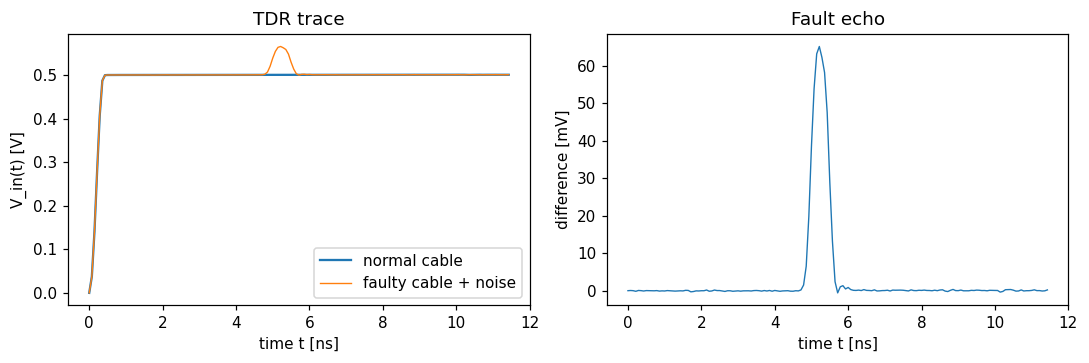

In [ ]:
_, v_nom = measured_trace(np.full(NX, R0), np.full(NX, C0), 0.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(t*1e9, v_nom, label='normal cable'); ax[0].plot(t*1e9, v_meas, label='faulty cable + noise', lw=.9)
ax[0].set_xlabel('time t [ns]'); ax[0].set_ylabel('V_in(t) [V]'); ax[0].legend(); ax[0].set_title('TDR trace')
ax[1].plot(t*1e9, (v_meas - v_nom)*1e3, lw=.9)
ax[1].set_xlabel('time t [ns]'); ax[1].set_ylabel('difference [mV]'); ax[1].set_title('Fault echo')
plt.tight_layout(); plt.show()

### Figure 2: reconstructed R(x) and C(x) against the truth

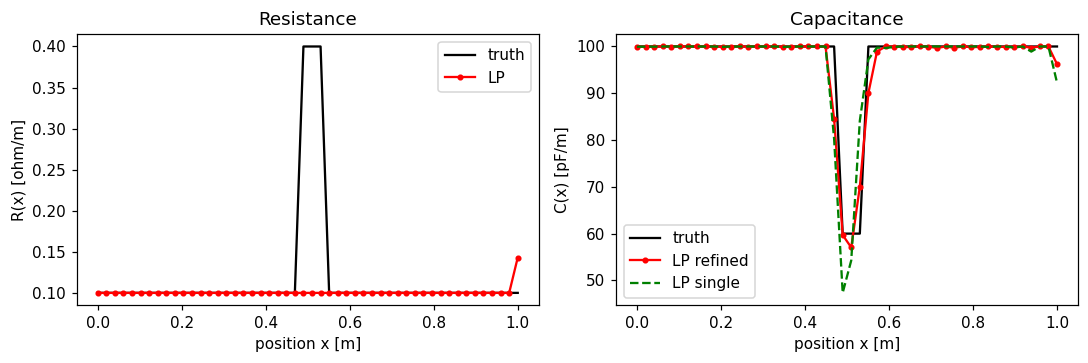

In [ ]:
x = np.arange(NX) * DX
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(x, R_true, 'k-', label='truth'); ax[0].plot(x, R_rec, 'r.-', label='LP')
ax[0].set_xlabel('position x [m]'); ax[0].set_ylabel('R(x) [ohm/m]'); ax[0].legend(); ax[0].set_title('Resistance')
ax[1].plot(x, C_true*1e12, 'k-', label='truth'); ax[1].plot(x, C_rec*1e12, 'r.-', label='LP refined')
ax[1].plot(x, C0*(1-d1)*1e12, 'g--', label='LP single')
ax[1].set_xlabel('position x [m]'); ax[1].set_ylabel('C(x) [pF/m]'); ax[1].legend(); ax[1].set_title('Capacitance')
plt.tight_layout(); plt.show()

### Figure 3: residual (how well the answer explains the recording)

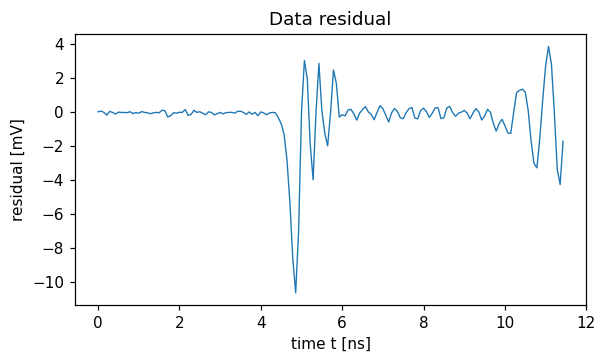

In [ ]:
_, v_fit = model_trace(r3, d3); _, v_nm = model_trace(np.zeros(NX), np.zeros(NX))
target = v_meas - ref + v_nm
plt.figure(figsize=(6, 3.2)); plt.plot(t*1e9, (target - v_fit)*1e3, lw=.9)
plt.xlabel('time t [ns]'); plt.ylabel('residual [mV]'); plt.title('Data residual'); plt.show()

### Effect of measurement noise on the recovered fault location

In [ ]:
sigmas = [0.0, 1e-5, 1e-4, 1e-3]
base = fault_location(invert(measured_trace(R_true, C_true, 0.0)[1], 0, v_ref=ref)[1])
for sg in sigmas:
    locs = [fault_location(invert(measured_trace(R_true, C_true, sg, seed=k)[1], 0, v_ref=ref)[1]) for k in range(10)]
    print(f'noise {sg:.0e} V: largest shift = {np.abs(np.array(locs) - base).max():.2f} cells')

noise 0e+00 V: largest shift = 0.00 cells
noise 1e-05 V: largest shift = 0.00 cells
noise 1e-04 V: largest shift = 0.00 cells
noise 1e-03 V: largest shift = 0.03 cells


### Result and Discussion

The simulation locates a hidden fault in a 1 m cable from nothing but the voltage recorded at the input end.

* **Echo (Figure 1):** The faulty cable's trace differs from the normal cable's by a clear echo of about 65 mV on a 1 V step, arriving at roughly 5.2 ns. This matches the expected travel time to $x \approx 0.5$ m and back, $2x/v_0 = 5.0$ ns, with $v_0 = 2\times10^8$ m/s.

* **Stability:** The Courant number is 0.70 on the normal cable and 0.904 at the fault, where the lower capacitance makes the wave faster. Both are below 1, so the explicit scheme remains stable.

* **Linear Program:** The matrix $A$ has shape $161 \times 100$ (time samples $\times$ unknowns, i.e. $R$ and $C$ at 50 nodes). `linprog` solved both the single LP and the refined version successfully, and the recovered $R$ and $C$ are non-negative everywhere.

* **Fault Location (Figure 2):** The true fault is centred at node 25 ($x \approx 0.510$ m). The single LP places it at node 24.43 ($x \approx 0.499$ m) and the refined LP at node 24.68 ($x \approx 0.504$ m), i.e. within about one cell ($\Delta x \approx 0.02$ m) of the truth.

* **Fault Size:** The true capacitance dip is 40 % ($C = 0.6\,C_0$). The single LP overestimates it at about 53 %, and the two refinement steps bring it to about 43 %, which shows the benefit of re-linearising.

* **Data Fit (Figure 3):** The refined model explains the recording to an RMS residual of about 1.6 mV, small compared with the 65 mV echo.

* **Noise Sensitivity:** For noise levels of 0, $10^{-5}$ and $10^{-4}$ V the recovered location did not move at all across 10 random noise draws. Even at $10^{-3}$ V (1 mV) the largest shift was only 0.03 cells. The location is therefore robust to noise.

* **Limitation:** The capacitance dip is found clearly, but the **resistance spike is not reliably found**. The extra resistance changes the signal by only about one part in 10,000, which is hidden under the capacitance echo, and the recovered $R$ profile does not peak at the fault. A planned improvement is to fit $C$ first and then fit $R$ on the remaining residual.

**Result**

The finite difference model of the telegrapher equations, combined with an $\ell_1$ linear program, locates the hidden fault to within about one grid cell and recovers the capacitance defect to within a few percent after refinement, even in the presence of measurement noise. The resistance defect cannot yet be recovered reliably.
